In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.datasets import boston_housing

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print(f"Tensorflow version: {tf.__version__} ")

Tensorflow version: 2.21.0 


In [ ]:
# Load the Dataset
(X_train, Y_train), (X_test, Y_test) = boston_housing.load_data()

print(f"Training features shape : {X_train.shape}")
print(f"Training targets shape : {Y_train.shape}")
print(f"Testing features shape : {X_test.shape}")
print(f"Testing targets shape : {Y_test.shape}")

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training features shape : (404, 13)
Training targets shape : (404,)
Testing features shape : (102, 13)
Testing targets shape : (102,)


In [ ]:
# Feature Normalization / Scaling
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

x_train_scaled = (X_train - mean) / std
x_test_scaled = (X_test - mean) / std

print(f"Feature Normalized successfully using Z-scored standardization")

Feature Normalized successfully using Z-scored standardization


In [ ]:
# Build the Deep Neural Network Model
model = Sequential([
    Input(shape=(13,)),
    Dense(64, activation="relu", name="hidden_layer1"),
    Dense(32, activation="relu", name="hidden_layer2"),
    Dense(16, activation="relu", name="hidden_layer3"),
    Dense(1, activation="linear", name="output_layer")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer1 (Dense)           │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer3 (Dense)           │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the Model
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [ ]:
# Train the Model
EPOCH = 100
BATCH_SIZE = 16

history = model.fit(x_train_scaled, Y_train, batch_size=BATCH_SIZE,
                    epochs=EPOCH, verbose=1, validation_split=0.2)


Epoch 1/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 550.9012 - mae: 21.6012 - val_loss: 590.8549 - val_mae: 22.4608
Epoch 2/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 475.1721 - mae: 19.7723 - val_loss: 478.2161 - val_mae: 19.8255
Epoch 3/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 332.3885 - mae: 15.9219 - val_loss: 287.7715 - val_mae: 14.5475
Epoch 4/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 153.1981 - mae: 9.9747 - val_loss: 112.4836 - val_mae: 8.1599
Epoch 5/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 69.4990 - mae: 6.3860 - val_loss: 67.7156 - val_mae: 6.3989
Epoch 6/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 46.8124 - mae: 5.0042 - val_loss: 48.2086 - val_mae: 5.1649
Epoch 7/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 34.2120 - mae: 4.1510 - val_loss: 36.5046 - val_mae: 4.4829
Epoch 8/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 27.9466 - mae: 3.6933 - val_loss: 30.9349 - val_mae: 4.1572
Epoch 9/100
21/21 ━━━━━━━━━━━━━━━

In [ ]:
# Evaluate Model on Test Set
test_mse, test_mae = model.evaluate(x_test_scaled, Y_test, verbose=0)

print(f"\n >> Final Test Performance: ")
print(f"Mean Squared Error (MSE) : {test_mse:.2f}")
print(f"Mean Absolute Error (MAE): ${test_mae * 1000:.2f}")


 >> Final Test Performance: 
Mean Squared Error (MSE) : 16.58
Mean Absolute Error (MAE): $2660.90


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


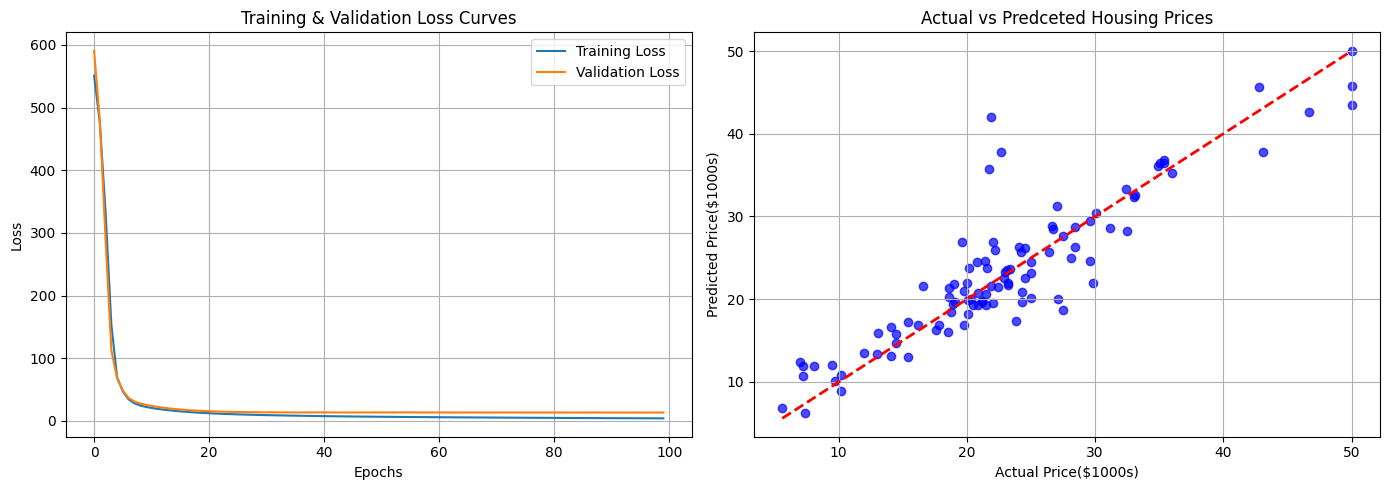


--- Sample Predictions Output ---
 Actual Price  Predicted Price  Difference
          7.2        10.740000    3.540000
         18.8        18.400000    0.400000
         19.0        21.820000    2.820000
         27.0        31.309999    4.309999
         22.2        25.959999    3.759999
         24.5        22.520000    1.980000
         31.2        28.590000    2.610000
         22.9        22.510000    0.390000
         20.5        19.320000    1.180000
         23.2        21.969999    1.230001


In [ ]:
# Visualize Training Curves &amp; Predictions
plt.figure(figsize=(14,5))

# Plot 1: Loss (MSE) Over Epochs
plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training & Validation Loss Curves")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Plot 2: Actual vs Predicted Prices
y_pred = model.predict(x_test_scaled).flatten()
plt.subplot(1,2,2)
plt.scatter(Y_test, y_pred, color="blue", alpha=0.7)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()],'r--',lw=2)
plt.title("Actual vs Predceted Housing Prices")
plt.xlabel("Actual Price($1000s)")
plt.ylabel("Predicted Price($1000s)")
plt.grid(True)

plt.tight_layout()
plt.show()

# Sample output comparison table for demonstration
sample_df = pd.DataFrame({
    'Actual Price': Y_test[:10],
    'Predicted Price': np.round(y_pred[:10],2),
    'Difference' : np.abs(Y_test[:10] - np.round(y_pred[:10],2))
})
print("\n--- Sample Predictions Output ---")
print(sample_df.to_string(index=False))